# Deep Learning Laboratory - Mini Project

## Baseline versus Advanced Image Classifier

This is a standalone notebook for this lab section. Run the setup and dataset cells first, then run the experiment cell and its output check. Use a Colab GPU runtime for the image and generative-model experiments when available.


## Step 1 — Install the Additional Colab Packages

Wait until installation completes before the next cell starts.

In [ ]:
%pip -q install -U datasets "transformers<5" sentencepiece accelerate torchmetrics torch-fidelity ucimlrepo tabulate


## Step 2 — Verify the Runtime

This cell records the Python, TensorFlow, and PyTorch versions and enables safe TensorFlow GPU memory growth.

In [ ]:
from pathlib import Path
import platform
import tensorflow as tf
import torch

project_root = Path("/content/Deeplearning")
project_root.mkdir(parents=True, exist_ok=True)
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
print(f"Python: {platform.python_version()}")
print(f"TensorFlow: {tf.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Project root: {project_root}")


Python: 3.13.15
TensorFlow: 2.20.0
PyTorch: 2.11.0+cu128
CUDA available: True
Project root: /content/Deeplearning


## Step 3 — Import Every Required Dataset

This cell creates visible files under `/content/Deeplearning/datasets` and prints a manifest that can be shown to the staff.

- MNIST, Iris, CIFAR-10, Dogs vs. Cats, Airline Passengers, and Tiny Shakespeare are downloaded as complete or balanced lab-ready files.
- MS COCO, CelebA, and LSUN Bedrooms are the genuine named datasets, streamed as practical subsets for Colab.
- No synthetic replacement dataset is used.

In [ ]:
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from datasets import load_dataset
from sklearn.datasets import load_iris


root = Path("/content/Deeplearning") if Path("/content").exists() else Path(__file__).resolve().parent
dataset_dir = root / "datasets"
output_dir = root / "outputs"
dataset_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)


def balanced_indices(labels, per_class, seed):
    labels = np.asarray(labels).reshape(-1)
    indices = np.concatenate([np.flatnonzero(labels == class_index)[:per_class] for class_index in np.unique(labels)])
    rng = np.random.default_rng(seed)
    rng.shuffle(indices)
    return indices


def save_image_stream(dataset_name, split, destination, count, size, config=None):
    destination.mkdir(parents=True, exist_ok=True)
    existing = sorted(destination.glob("*.jpg"))
    if len(existing) >= count:
        return len(existing)
    arguments = {
        "path": dataset_name,
        "split": split,
        "streaming": True,
    }
    if config is not None:
        arguments["name"] = config
    stream = load_dataset(**arguments)
    saved = 0
    for row in stream.take(count):
        image = row["image"].convert("RGB")
        image = image.resize((size, size), Image.Resampling.LANCZOS)
        image.save(destination / f"image_{saved:04d}.jpg", quality=92)
        saved += 1
    if saved < count:
        raise RuntimeError(f"Only {saved} images were available from {dataset_name}")
    return saved


(mnist_x_train, mnist_y_train), (mnist_x_test, mnist_y_test) = tf.keras.datasets.mnist.load_data()
mnist_train_indices = balanced_indices(mnist_y_train, 1000, 42)
mnist_test_indices = balanced_indices(mnist_y_test, 200, 42)
np.savez_compressed(
    dataset_dir / "mnist_lab.npz",
    x_train=mnist_x_train[mnist_train_indices],
    y_train=mnist_y_train[mnist_train_indices],
    x_test=mnist_x_test[mnist_test_indices],
    y_test=mnist_y_test[mnist_test_indices],
)

try:
    from ucimlrepo import fetch_ucirepo

    iris_repository = fetch_ucirepo(id=53)
    iris_features = iris_repository.data.features.copy()
    iris_features.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
    iris_target = iris_repository.data.targets.iloc[:, 0].astype(str)
    iris_target = iris_target.str.replace("Iris-", "", regex=False).str.replace("Iris ", "", regex=False).str.lower()
    iris = iris_features.copy()
    iris["species"] = iris_target.to_numpy()
    iris_source = "UCI Machine Learning Repository dataset 53"
except Exception:
    iris_bundle = load_iris(as_frame=True)
    iris = iris_bundle.data.copy()
    iris.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
    iris["species"] = pd.Series(iris_bundle.target).map(dict(enumerate(iris_bundle.target_names)))
    iris_source = "scikit-learn packaged Iris fallback"
iris.to_csv(dataset_dir / "iris.csv", index=False)

(cifar_x_train, cifar_y_train), (cifar_x_test, cifar_y_test) = tf.keras.datasets.cifar10.load_data()
cifar_train_indices = balanced_indices(cifar_y_train, 800, 42)
cifar_test_indices = balanced_indices(cifar_y_test, 200, 42)
np.savez_compressed(
    dataset_dir / "cifar10_lab.npz",
    x_train=cifar_x_train[cifar_train_indices],
    y_train=cifar_y_train[cifar_train_indices].reshape(-1),
    x_test=cifar_x_test[cifar_test_indices],
    y_test=cifar_y_test[cifar_test_indices].reshape(-1),
)

def build_cats_and_dogs_filtered(destination, image_size=160, seed=42):
    """Rebuild the classic 'cats_and_dogs_filtered' train/validation layout.

    The original tutorial archive at
    https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip
    now returns HTTP 403 (Google retired the mledu-datasets bucket), so the
    same 3,000-image split is reconstructed by streaming labelled images
    from the public "microsoft/cats_vs_dogs" dataset on the Hugging Face Hub.
    """
    targets = {
        destination / "train" / "cats": (0, 1000),
        destination / "train" / "dogs": (1, 1000),
        destination / "validation" / "cats": (0, 500),
        destination / "validation" / "dogs": (1, 500),
    }
    already_done = all(
        len(list(folder.glob("*.jpg"))) >= count for folder, (_, count) in targets.items()
    )
    if already_done:
        return destination
    for folder in targets:
        folder.mkdir(parents=True, exist_ok=True)
    counts = {folder: 0 for folder in targets}
    stream = load_dataset("microsoft/cats_vs_dogs", split="train", streaming=True)
    stream = stream.shuffle(seed=seed, buffer_size=2000)
    for row in stream:
        if all(counts[folder] >= count for folder, (_, count) in targets.items()):
            break
        label = row["labels"]
        for folder, (target_label, target_count) in targets.items():
            if label != target_label or counts[folder] >= target_count:
                continue
            try:
                image = row["image"].convert("RGB")
            except Exception:
                break
            image = image.resize((image_size, image_size), Image.Resampling.LANCZOS)
            image.save(folder / f"image_{counts[folder]:04d}.jpg", quality=92)
            counts[folder] += 1
            break
    for folder, (_, count) in targets.items():
        if counts[folder] < count:
            raise RuntimeError(f"Only {counts[folder]} images were available for {folder}")
    return destination


dogs_cats_dir = dataset_dir / "cats_and_dogs_filtered"
build_cats_and_dogs_filtered(dogs_cats_dir)
if not (dogs_cats_dir / "train").exists():
    raise FileNotFoundError("Dogs vs. Cats extraction folder was not created")

airline_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/refs/heads/master/monthly-airline-passengers.csv"
airline = pd.read_csv(airline_url)
airline.to_csv(dataset_dir / "monthly_airline_passengers.csv", index=False)

shakespeare_cache = tf.keras.utils.get_file(
    fname="shakespeare.txt",
    origin="https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt",
    cache_dir=str(root),
    cache_subdir="downloads",
)
shakespeare_path = dataset_dir / "shakespeare.txt"
shutil.copyfile(shakespeare_cache, shakespeare_path)

coco_dir = dataset_dir / "ms_coco_subset"
coco_dir.mkdir(parents=True, exist_ok=True)
coco_caption_path = coco_dir / "captions.csv"
if not coco_caption_path.exists() or len(list(coco_dir.glob("coco_*.jpg"))) < 5:
    coco_stream = load_dataset("mm-eval/MS-COCO-Captions", split="val", streaming=True)
    coco_rows = []
    for index, row in enumerate(coco_stream.take(5)):
        image_path = coco_dir / f"coco_{index:03d}.jpg"
        media = row["media"]
        image = media[0] if isinstance(media, list) else media
        image.convert("RGB").save(image_path, quality=92)
        coco_rows.append(
            {
                "file": image_path.name,
                "captions_json": json.dumps(list(row["answer"]), ensure_ascii=False),
            }
        )
    pd.DataFrame(coco_rows).to_csv(coco_caption_path, index=False)

celeba_dir = dataset_dir / "celeba_subset"
celeba_count = save_image_stream("flwrlabs/celeba", "train", celeba_dir, 384, 64, "img_align+identity+attr")

lsun_dir = dataset_dir / "lsun_bedrooms_subset"
lsun_count = save_image_stream("pcuenq/lsun-bedrooms", "train", lsun_dir, 512, 64)

manifest = pd.DataFrame(
    [
        {"dataset": "MNIST", "path": "mnist_lab.npz", "records": 12000, "experiments": "1", "source": "TensorFlow Keras MNIST", "scope": "Balanced lab subset"},
        {"dataset": "Iris", "path": "iris.csv", "records": len(iris), "experiments": "2", "source": iris_source, "scope": "Complete dataset"},
        {"dataset": "CIFAR-10", "path": "cifar10_lab.npz", "records": 10000, "experiments": "3, 4, Mini Project", "source": "TensorFlow Keras CIFAR-10", "scope": "Balanced lab subset"},
        {"dataset": "Dogs vs. Cats", "path": str(dogs_cats_dir.relative_to(dataset_dir)), "records": 3000, "experiments": "5", "source": "microsoft/cats_vs_dogs public mirror (Hugging Face)", "scope": "Filtered dataset (rebuilt 1000/1000 train, 500/500 validation)"},
        {"dataset": "Airline Passengers", "path": "monthly_airline_passengers.csv", "records": len(airline), "experiments": "6", "source": airline_url, "scope": "Complete dataset"},
        {"dataset": "MS COCO", "path": "ms_coco_subset", "records": 5, "experiments": "7", "source": "mm-eval/MS-COCO-Captions public parquet mirror", "scope": "Real-image demonstration subset"},
        {"dataset": "CelebA", "path": "celeba_subset", "records": celeba_count, "experiments": "8", "source": "flwrlabs/celeba public mirror", "scope": "Streamed training subset"},
        {"dataset": "Shakespeare Corpus", "path": "shakespeare.txt", "records": len(shakespeare_path.read_text(encoding="utf-8")), "experiments": "9", "source": "TensorFlow Tiny Shakespeare", "scope": "Complete corpus"},
        {"dataset": "LSUN Bedrooms", "path": "lsun_bedrooms_subset", "records": lsun_count, "experiments": "10", "source": "pcuenq/lsun-bedrooms public mirror", "scope": "Streamed training subset"},
    ]
)
manifest.to_csv(dataset_dir / "dataset_manifest.csv", index=False)

print(f"Deeplearning root: {root}")
print(manifest.to_string(index=False))
print("Dataset evidence:")
for path in sorted(dataset_dir.iterdir()):
    if path.is_dir():
        file_count = sum(1 for item in path.rglob("*") if item.is_file())
        print(f"{path.name}/: {file_count} files")
    else:
        print(f"{path.name}: {path.stat().st_size} bytes")


Deeplearning root: /content/Deeplearning
           dataset                           path  records        experiments                                                                                                source                                                          scope
             MNIST                  mnist_lab.npz    12000                  1                                                                                TensorFlow Keras MNIST                                            Balanced lab subset
              Iris                       iris.csv      150                  2                                                            UCI Machine Learning Repository dataset 53                                               Complete dataset
          CIFAR-10                cifar10_lab.npz    10000 3, 4, Mini Project                                                                             TensorFlow Keras CIFAR-10                                            Balance

# Mini Project — Baseline versus Advanced Image Classifier

**Dataset:** CIFAR-10

**Procedure:** Compares an MLP baseline with an augmented CNN using test accuracy, macro F1, and a confusion matrix.

Run the cell and wait for the completion message. The model, numerical results, and plots are written to the corresponding folder under `/content/Deeplearning/outputs`.

Epoch 1/4
107/107 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.1893 - loss: 2.2298 - val_accuracy: 0.2608 - val_loss: 2.0431
Epoch 2/4
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2599 - loss: 2.0118 - val_accuracy: 0.2783 - val_loss: 1.9402
Epoch 3/4
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2835 - loss: 1.9594 - val_accuracy: 0.3142 - val_loss: 1.9069
Epoch 4/4
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2894 - loss: 1.9323 - val_accuracy: 0.3033 - val_loss: 1.9067
{'model': 'Baseline MLP', 'test_accuracy': 0.329, 'macro_f1': 0.3099540340107348}
Epoch 1/4
107/107 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.2559 - loss: 2.0222 - val_accuracy: 0.1133 - val_loss: 2.3797
Epoch 2/4
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.3291 - loss: 1.7918 - val_accuracy: 0.1400 - val_loss: 2.5561
Epoch 3/4
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.3774 - loss: 1.6623 - val_accuracy: 0.1242 - val_loss: 2.5054
Epoch 4/4
107/107 ━━━━━━━

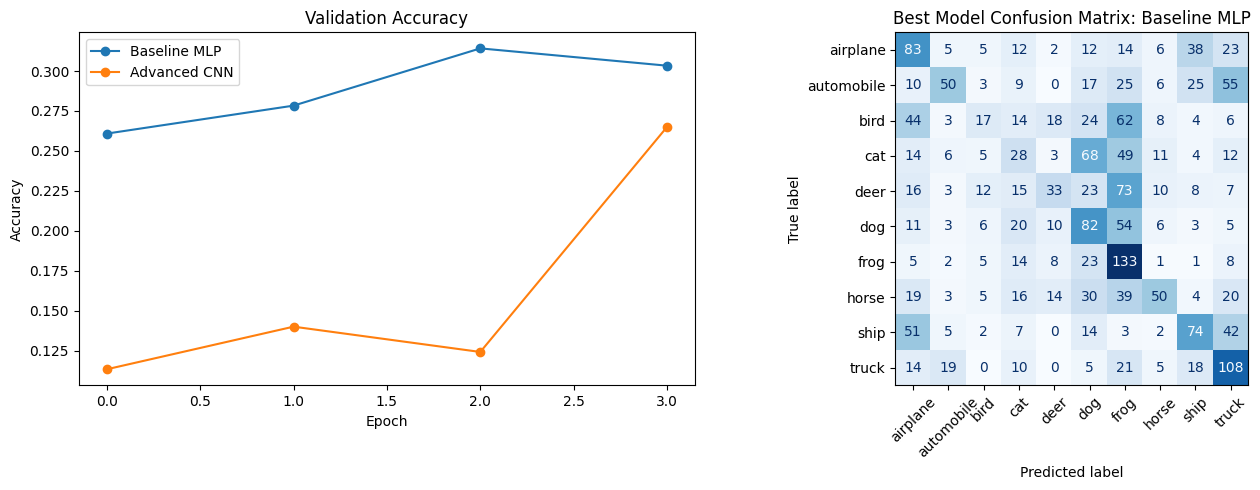

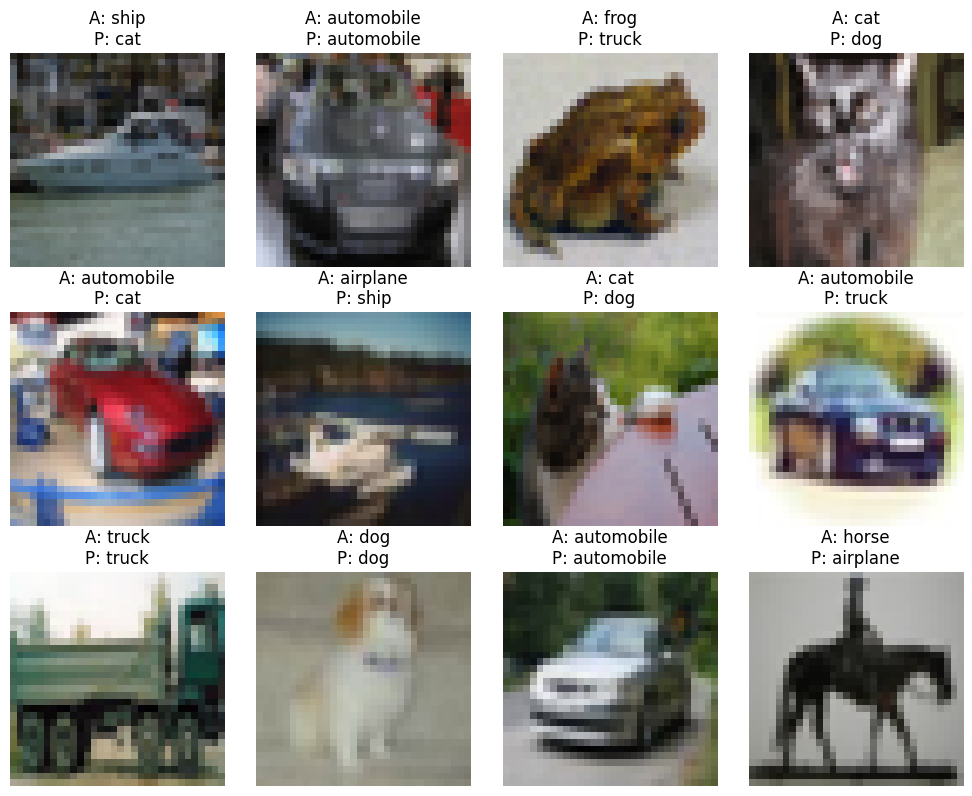

Mini project completed
       model  test_accuracy  macro_f1
Baseline MLP          0.329  0.309954
Advanced CNN          0.252  0.200931
Output folder: /content/Deeplearning/outputs/mini_project


In [ ]:
from pathlib import Path
import gc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score


try:
    import torch

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
except Exception:
    pass
gc.collect()

root = Path("/content/Deeplearning") if Path("/content").exists() else Path(__file__).resolve().parents[1]
dataset_path = root / "datasets" / "cifar10_lab.npz"
output_dir = root / "outputs" / "mini_project"
output_dir.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(42)
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

with np.load(dataset_path) as dataset:
    X_train = dataset["x_train"].astype("float32") / 255.0
    y_train = dataset["y_train"].astype("int64")
    X_test = dataset["x_test"].astype("float32") / 255.0
    y_test = dataset["y_test"].astype("int64")


def build_baseline():
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(32, 32, 3)),
            tf.keras.layers.Flatten(),
            tf.keras.layers.Dense(256, activation="relu"),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(10, activation="softmax"),
        ]
    )


def build_advanced():
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(32, 32, 3)),
            tf.keras.layers.RandomFlip("horizontal"),
            tf.keras.layers.RandomRotation(0.05),
            tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
            tf.keras.layers.MaxPooling2D(),
            tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
            tf.keras.layers.MaxPooling2D(),
            tf.keras.layers.GlobalAveragePooling2D(),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(10, activation="softmax"),
        ]
    )


results = []
histories = {}
predictions_by_model = {}
for model_name, builder in [("Baseline MLP", build_baseline), ("Advanced CNN", build_advanced)]:
    model = builder()
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    history = model.fit(X_train, y_train, validation_split=0.15, epochs=4, batch_size=64, verbose=1)
    probabilities = model.predict(X_test, batch_size=256, verbose=0)
    predictions = probabilities.argmax(axis=1)
    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")
    results.append({"model": model_name, "test_accuracy": accuracy, "macro_f1": macro_f1})
    histories[model_name] = history.history
    predictions_by_model[model_name] = predictions
    model.save(output_dir / f"{model_name.lower().replace(' ', '_')}.keras")
    print({"model": model_name, "test_accuracy": accuracy, "macro_f1": macro_f1})

comparison = pd.DataFrame(results).sort_values("test_accuracy", ascending=False)
comparison.to_csv(output_dir / "mini_project_model_comparison.csv", index=False)
best_model_name = comparison.iloc[0]["model"]
best_predictions = predictions_by_model[best_model_name]

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
for model_name, history in histories.items():
    axes[0].plot(history["val_accuracy"], marker="o", label=model_name)
axes[0].set_title("Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions, display_labels=class_names, cmap="Blues", colorbar=False, xticks_rotation=45, ax=axes[1])
axes[1].set_title(f"Best Model Confusion Matrix: {best_model_name}")
figure.tight_layout()
figure.savefig(output_dir / "mini_project_evaluation.png", dpi=180, bbox_inches="tight")
plt.show()

report = f"""# Deep Learning Mini Project

## Topic

CIFAR-10 image classification using a baseline multilayer perceptron and an advanced convolutional neural network.

## Dataset

A balanced real CIFAR-10 lab subset containing 8,000 training images and 2,000 test images across ten classes.

## Methodology

The baseline flattens each image and classifies it with a dense neural network. The advanced model preserves spatial information with convolution, batch normalization, pooling, augmentation, and global average pooling. Both models use the same train and test records.

## Results

{comparison.to_markdown(index=False)}

## Findings

The best model was {best_model_name}. Its test accuracy was {comparison.iloc[0]['test_accuracy']:.4f} and its macro F1-score was {comparison.iloc[0]['macro_f1']:.4f}. The comparison demonstrates the value of image-specific convolutional features over a flattened-pixel baseline.

## Challenges

The experiment uses a Colab-safe balanced subset and four training epochs, so the result is a reproducible lab demonstration rather than a production benchmark.

## Future Work

Use the complete CIFAR-10 training set, longer training, learning-rate scheduling, stronger augmentation, and transfer learning.
"""
(output_dir / "mini_project_report.md").write_text(report, encoding="utf-8")

sample_indices = np.arange(12)
sample_figure, sample_axes = plt.subplots(3, 4, figsize=(10, 8))
for index, axis in zip(sample_indices, sample_axes.ravel()):
    axis.imshow(X_test[index])
    axis.set_title(f"A: {class_names[y_test[index]]}\nP: {class_names[best_predictions[index]]}")
    axis.axis("off")
sample_figure.tight_layout()
sample_figure.savefig(output_dir / "mini_project_sample_predictions.png", dpi=180, bbox_inches="tight")
plt.show()

print("Mini project completed")
print(comparison.to_string(index=False))
print(f"Output folder: {output_dir}")


## Output check

Confirm that this experiment saved its results before moving on.

In [ ]:
from pathlib import Path
output_dir = Path('/content/Deeplearning/outputs/mini_project')
files = sorted(path for path in output_dir.rglob('*') if path.is_file())
assert files, f'No outputs found in {output_dir}; run the experiment cell first.'
print(f'{len(files)} output files saved in {output_dir}')
for path in files:
    print(path.relative_to(output_dir))
